In [57]:
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Visualization

In [58]:
clean_df = pd.read_csv("../processed/final_data.csv")
clean_df['date'] = pd.to_datetime(clean_df['date'])
clean_df.set_index('date', inplace=True)
clean_df

,tavg,tmin,tmax,prcp,wspd,pres,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),is_deleted
date,,,,,,,,,,,,,,,,,
2024-01-01,22.8,19,28.0,0.2,10.7,1016.8,70.26,47.10,55.50,37.39,29.63,650.33,0.76,0.59,0.12,1.13,False
2024-01-02,23.4,21,27.0,0.1,11.7,1016.0,53.51,35.83,61.54,30.05,21.92,512.04,0.94,0.56,0.00,1.23,False
2024-01-03,19.5,17,22.0,9.7,13.0,1019.9,42.76,29.72,53.21,18.25,19.08,648.83,0.31,0.42,0.25,1.20,False
2024-01-04,19.1,17,21.0,0.0,8.8,1019.0,70.36,48.32,38.42,41.70,33.64,899.71,0.45,0.54,0.12,1.18,False
2024-01-05,20.2,18,23.0,0.0,6.5,1017.6,86.80,56.93,50.00,47.55,36.79,1023.58,0.38,0.73,0.00,1.06,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-12-27,18.4,17,20.0,0.0,14.4,1024.2,58.57,58.35,57.29,38.22,23.88,809.71,0.39,0.54,0.00,1.07,False
2024-12-28,18.8,15,23.0,0.0,12.3,1025.9,52.32,52.15,68.54,34.94,26.61,912.38,0.99,0.36,0.00,1.18,False
2024-12-29,18.0,14,22.0,0.0,10.7,1021.5,84.19,83.82,74.88,55.83,41.59,905.38,1.01,0.56,0.29,1.01,False


In [59]:
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'axes.titlesize': 16,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'axes.labelweight': 'bold',
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 11,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
})

## Daily temperature

In [60]:
temp_mean = clean_df['tavg'].mean()

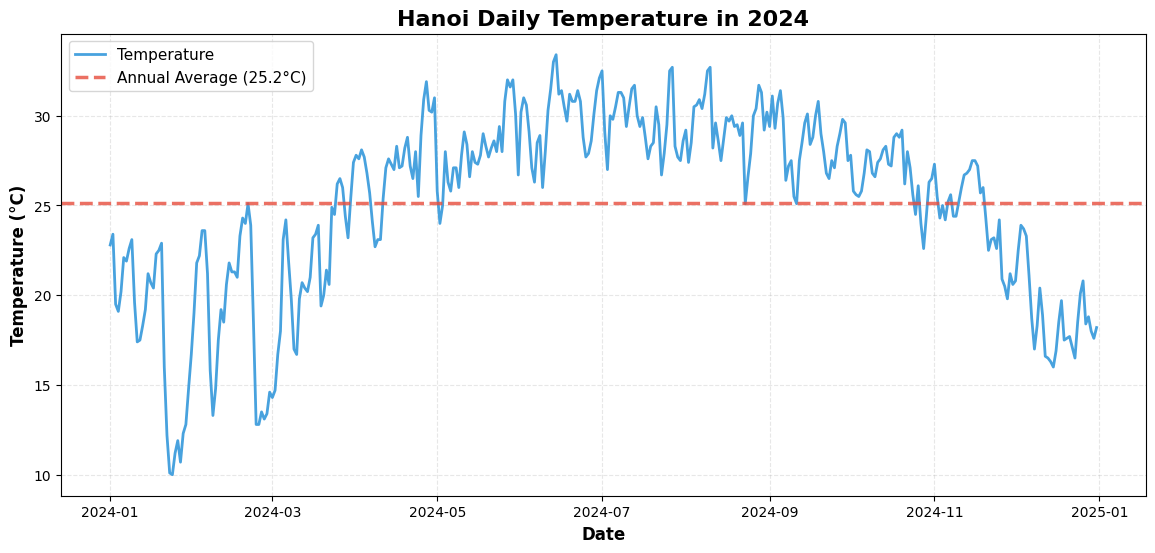

In [61]:
fig, ax = plt.subplots()
ax.plot(clean_df.index, clean_df['tavg'], 
         color='#3498db', linewidth=2, alpha=0.9, label='Temperature')
ax.axhline(y=temp_mean, color='#e74c3c', linestyle='--', linewidth=2.5, 
            label=f'Annual Average ({temp_mean:.1f}°C)', alpha=0.8)

ax.set_title('Hanoi Daily Temperature in 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Temperature (°C)')
ax.legend(loc='upper left')

fig.savefig("../figures/temp_over_time.png")
plt.show()

## PM2.5 & PM10

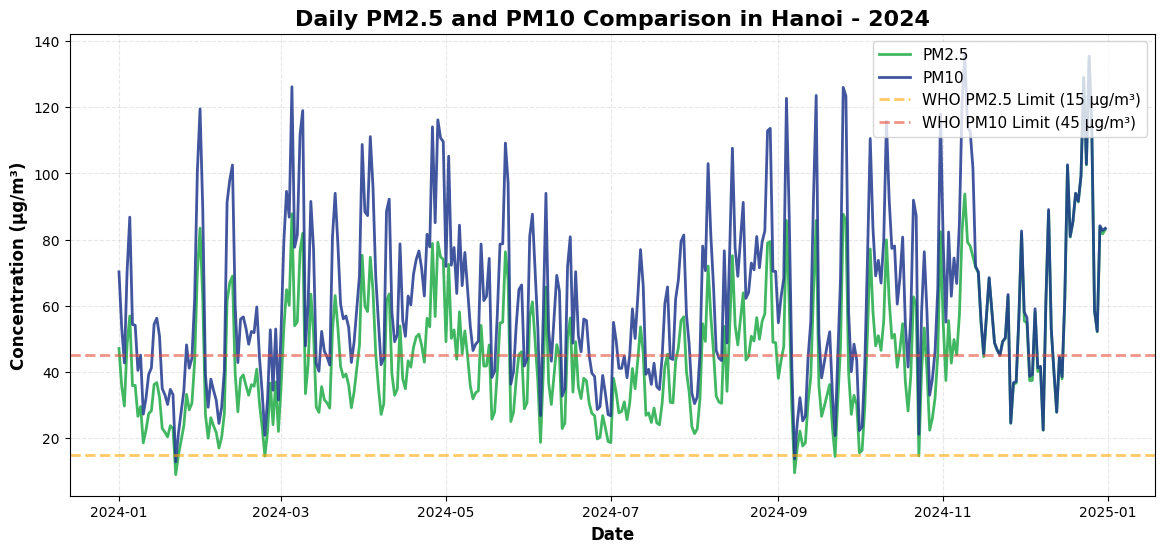

In [62]:
fig, ax = plt.subplots()
ax.plot(clean_df.index, clean_df['pm2_5 (μg/m³)'], 
         color="#1fab47", linewidth=2, alpha=0.85, label='PM2.5')
ax.plot(clean_df.index, clean_df['pm10 (μg/m³)'], 
         color="#1F388D", linewidth=2, alpha=0.85, label='PM10')

ax.axhline(y=15, color='orange', linestyle='--', linewidth=2, 
            label='WHO PM2.5 Limit (15 μg/m³)', alpha=0.6)
ax.axhline(y=45, color='#e74c3c', linestyle='--', linewidth=2, 
            label='WHO PM10 Limit (45 μg/m³)', alpha=0.6)

ax.set_title('Daily PM2.5 and PM10 Comparison in Hanoi - 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Concentration (μg/m³)')
ax.legend(loc='upper right')

fig.savefig("../figures/pm10_vs_pm2.5_over_time.png")
plt.show()

## PM2.5 Exceeded days

In [63]:
daily_pm25 = clean_df['pm2_5 (μg/m³)']
exceed_series = (daily_pm25 > 15).astype(int)
pm25_exceed = exceed_series.resample('M').sum()

C:\Users\Admin\AppData\Local\Temp\ipykernel_4140\3991649799.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  pm25_exceed = exceed_series.resample('M').sum()


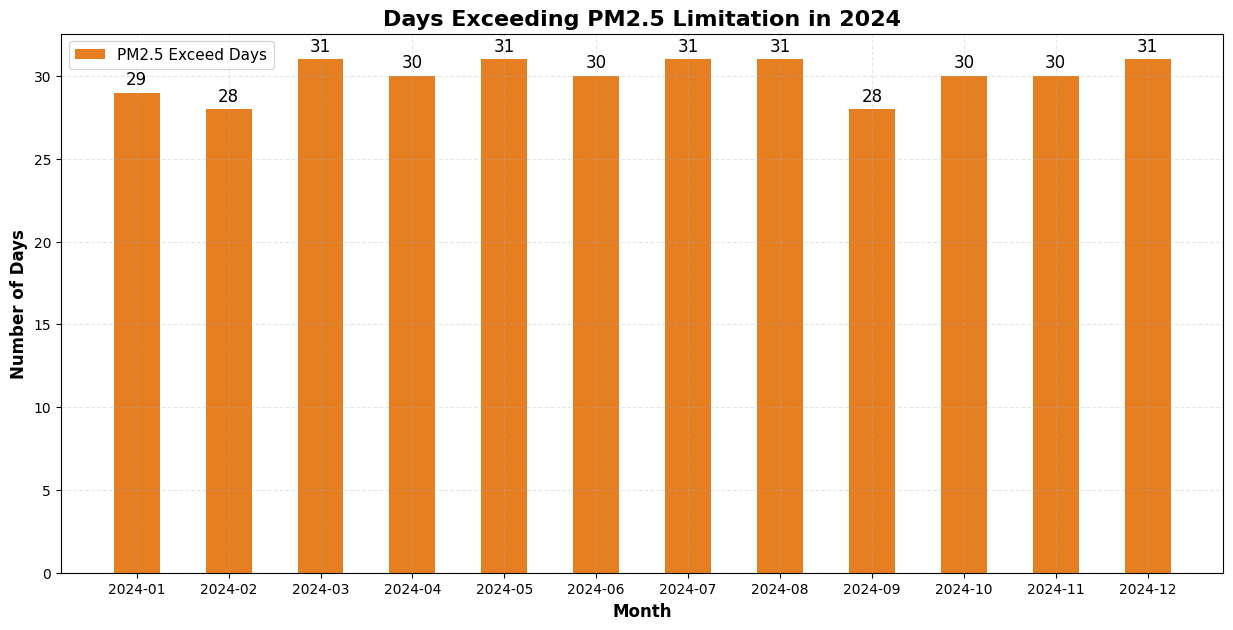

In [64]:
fig, ax = plt.subplots(figsize=(15, 7))

x_labels = pm25_exceed.index.strftime('%Y-%m')
bars = ax.bar(x_labels, pm25_exceed.values, color='#e67e22', label='PM2.5 Exceed Days', width=0.5)
ax.bar_label(bars, padding=3, fmt="%d", fontsize=12)

ax.set_title('Days Exceeding PM2.5 Limitation in 2024')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Days')
ax.legend()

fig.savefig('../figures/PM2.5_Exceed_Days.png')
plt.show()

## Heatmap hour x weekday

In [65]:
hourly_df = pd.read_csv("../raw/air_quality.csv")
hourly_df['time'] = pd.to_datetime(hourly_df['time'])
hourly_df['hour'] = hourly_df['time'].dt.hour
hourly_df['day_of_week'] = hourly_df['time'].dt.day_name()
hourly_df

,time,pm10 (μg/m³),pm2_5 (μg/m³),ozone (μg/m³),sulphur_dioxide (μg/m³),nitrogen_dioxide (μg/m³),carbon_dioxide (ppm),carbon_monoxide (μg/m³),uv_index (),aerosol_optical_depth (),dust (μg/m³),uv_index_clear_sky (),methane (μg/m³),hour,day_of_week
0,2024-01-01 00:00:00,59.8,40.0,26.0,36.0,36.8,NaN,702.0,0.0,0.46,0.0,0.0,NaN,0,Monday
1,2024-01-01 01:00:00,60.1,40.7,23.0,33.4,36.3,NaN,716.0,0.0,0.48,0.0,0.0,NaN,1,Monday
2,2024-01-01 02:00:00,61.7,42.0,20.0,31.6,35.7,NaN,732.0,0.0,0.52,0.0,0.0,NaN,2,Monday
3,2024-01-01 03:00:00,65.2,44.5,17.0,30.4,35.2,NaN,754.0,0.0,0.52,0.0,0.0,NaN,3,Monday
4,2024-01-01 04:00:00,68.9,47.1,15.0,30.5,35.1,NaN,778.0,0.0,0.51,0.0,0.0,NaN,4,Monday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8779,2024-12-31 19:00:00,101.7,101.5,51.0,47.8,41.9,476.0,1998.0,0.0,0.71,0.0,0.0,1747.0,19,Tuesday
8780,2024-12-31 20:00:00,105.2,104.8,49.0,49.3,41.0,477.0,1915.0,0.0,0.69,0.0,0.0,1766.0,20,Tuesday
8781,2024-12-31 21:00:00,108.5,108.3,46.0,51.2,39.6,477.0,1618.0,0.0,0.66,0.0,0.0,1765.0,21,Tuesday
8782,2024-12-31 22:00:00,112.9,112.7,43.0,51.4,38.1,477.0,1365.0,0.0,0.64,0.0,0.0,1765.0,22,Tuesday


In [66]:
heatmap_data = hourly_df.pivot_table(
    values='pm2_5 (μg/m³)', 
    index='hour', 
    columns='day_of_week', 
    aggfunc='mean'
)

In [67]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = heatmap_data.reindex(columns=day_order)
heatmap_data

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
hour,,,,,,,
0,48.849057,52.096226,54.605769,52.098077,53.417308,46.717308,48.978846
1,46.890566,49.467925,51.407692,49.388462,50.344231,44.505769,46.388462
2,45.198113,47.147170,48.955769,46.965385,47.994231,42.967308,44.032692
3,43.858491,45.100000,46.828846,45.263462,45.873077,41.863462,42.161538
4,42.569811,43.183019,45.161538,43.886538,43.998077,40.963462,40.563462
5,41.603774,42.147170,43.946154,43.200000,42.451923,40.153846,39.409615
6,42.190566,42.526415,44.061538,44.126923,42.571154,40.484615,39.753846
7,45.803774,44.875472,45.625000,46.348077,46.536538,43.425000,42.659615
8,44.060377,42.783019,43.325000,44.059615,44.538462,42.205769,41.269231


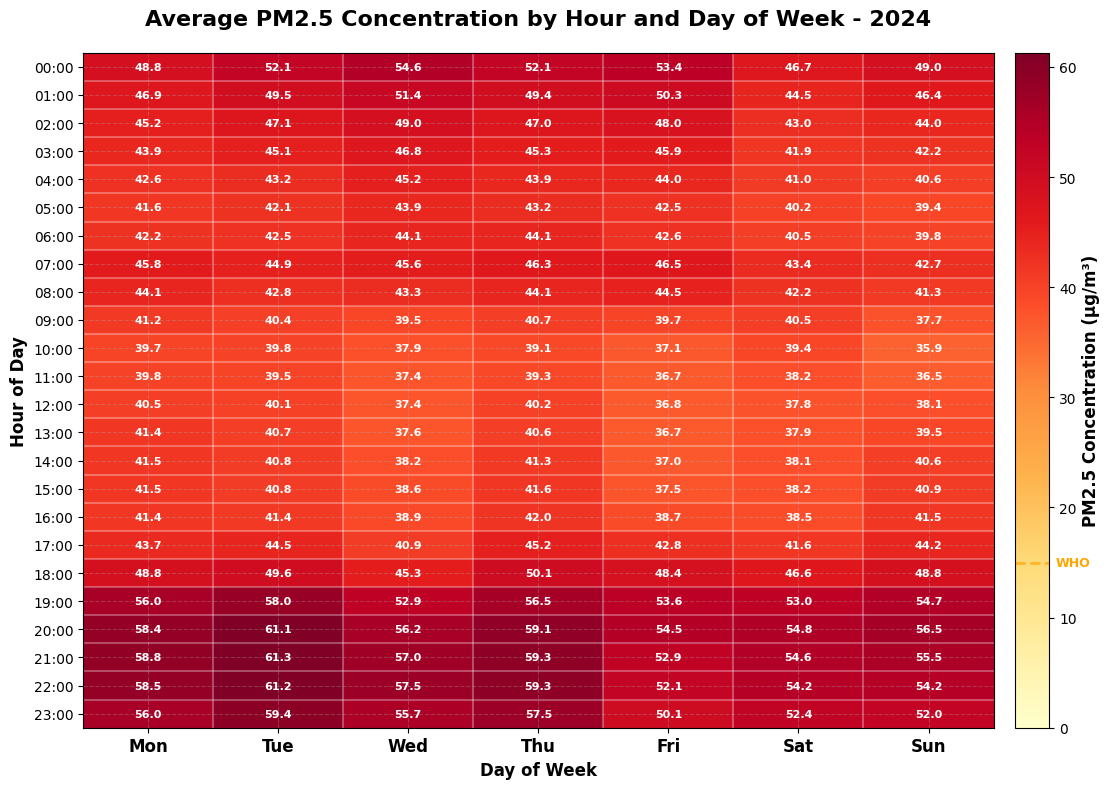

In [68]:
fig, ax = plt.subplots(figsize=(12, 8))

im = ax.imshow(heatmap_data.values, cmap='YlOrRd', aspect='auto', vmin=0)

ax.set_xticks(np.arange(len(day_order)))
ax.set_yticks(np.arange(24))
ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], 
                   fontsize=12, fontweight='bold')
ax.set_yticklabels([f'{h:02d}:00' for h in range(24)], fontsize=10)

for i in range(24):
    for j in range(len(day_order)):
        value = heatmap_data.values[i, j]
        color = 'white' if value > heatmap_data.values.max() * 0.5 else 'black'
        text = ax.text(j, i, f'{value:.1f}',
                       ha="center", va="center", 
                       color=color, fontsize=8, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, pad=0.02)
cbar.set_label('PM2.5 Concentration (μg/m³)', fontsize=12, fontweight='bold')
cbar.ax.tick_params(labelsize=10)

cbar.ax.axhline(y=15, color='orange', linestyle='--', linewidth=2, alpha=0.7)
cbar.ax.text(1.2, 15, 'WHO', va='center', fontsize=9, color='orange', fontweight='bold')

ax.set_title('Average PM2.5 Concentration by Hour and Day of Week - 2024', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Day of Week', fontsize=12, fontweight='bold')
ax.set_ylabel('Hour of Day', fontsize=12, fontweight='bold')

ax.set_xticks(np.arange(len(day_order)) - 0.5, minor=True)
ax.set_yticks(np.arange(24) - 0.5, minor=True)
ax.grid(which="minor", color="white", linestyle='-', linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)

plt.tight_layout()
plt.savefig("../figures/pm25_heatmap_hour_weekday.png", dpi=300, bbox_inches='tight')
plt.show()

## Rain days per month

C:\Users\Admin\AppData\Local\Temp\ipykernel_4140\2739661522.py:2: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  rain_days_monthly = daily_rain.resample('M').sum()


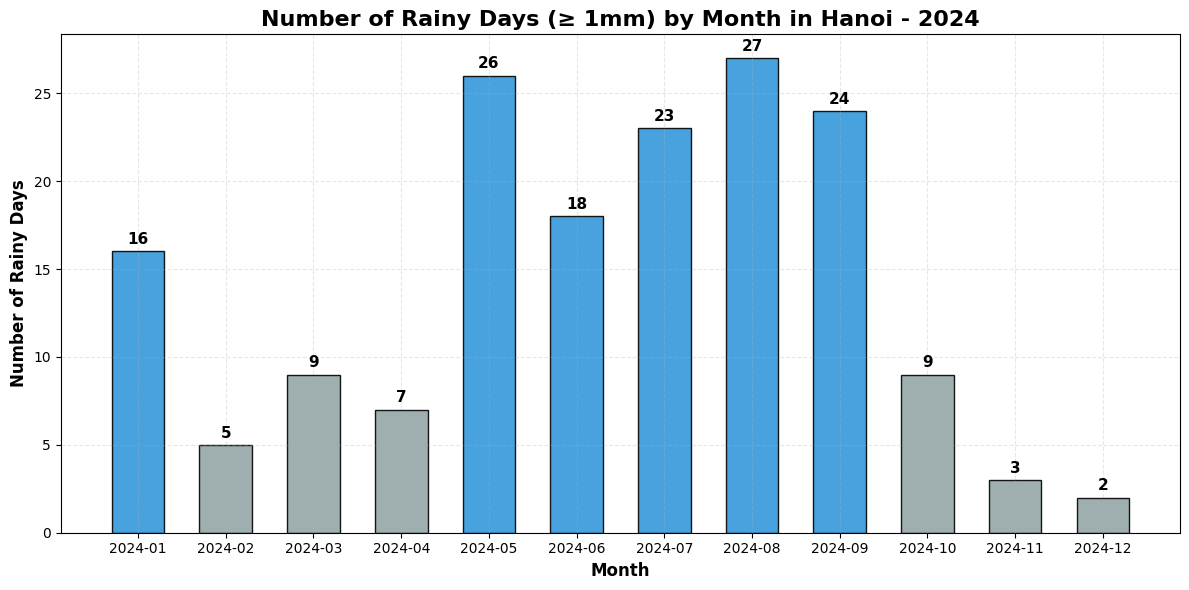

In [69]:
daily_rain = (clean_df['prcp'] >= 1).astype(int)
rain_days_monthly = daily_rain.resample('M').sum()

fig, ax = plt.subplots(figsize=(12, 6))

colors = ["#3498db" if x > 10 else '#95a5a6' for x in rain_days_monthly.values]

bars = ax.bar(x_labels, rain_days_monthly.values, color=colors, 
               edgecolor='black', linewidth=1, alpha=0.9, width=0.6)
ax.bar_label(bars, padding=3, fmt="%d", fontsize=11, fontweight='bold')

ax.set_title('Number of Rainy Days (≥ 1mm) by Month in Hanoi - 2024')
ax.set_xlabel('Month')
ax.set_ylabel('Number of Rainy Days')

plt.tight_layout()
plt.savefig("../figures/rain_days_by_month.png")
plt.show()

## Carbon Dioxide 

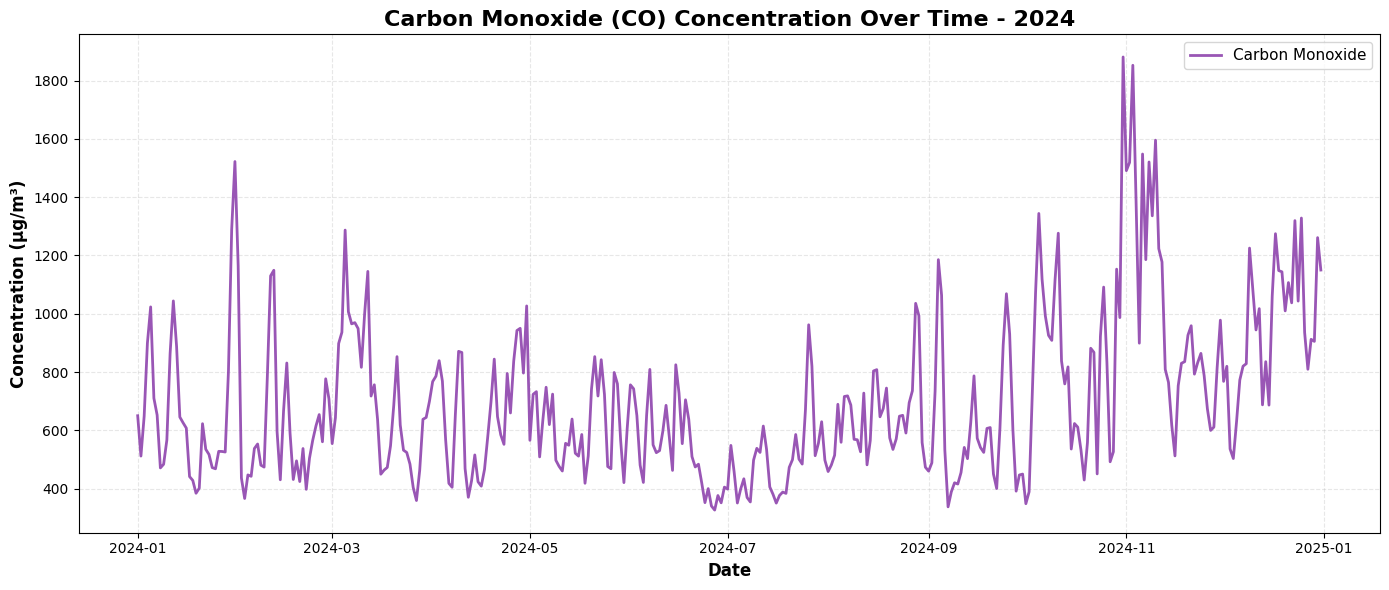

In [70]:
fig, ax = plt.subplots()

ax.plot(clean_df.index, clean_df['carbon_monoxide (μg/m³)'], 
         color='#8e44ad', linewidth=2, alpha=0.9, label='Carbon Monoxide')

ax.set_title('Carbon Monoxide (CO) Concentration Over Time - 2024')
ax.set_xlabel('Date')
ax.set_ylabel('Concentration (μg/m³)')
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig("../figures/CO_overtime.png")
plt.show()

## Rain & PM2.5 correlation

C:\Users\Admin\AppData\Local\Temp\ipykernel_4140\3570795094.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rain, x='filtered_rain', y='pm2_5 (μg/m³)', ax=ax, palette="Set2")


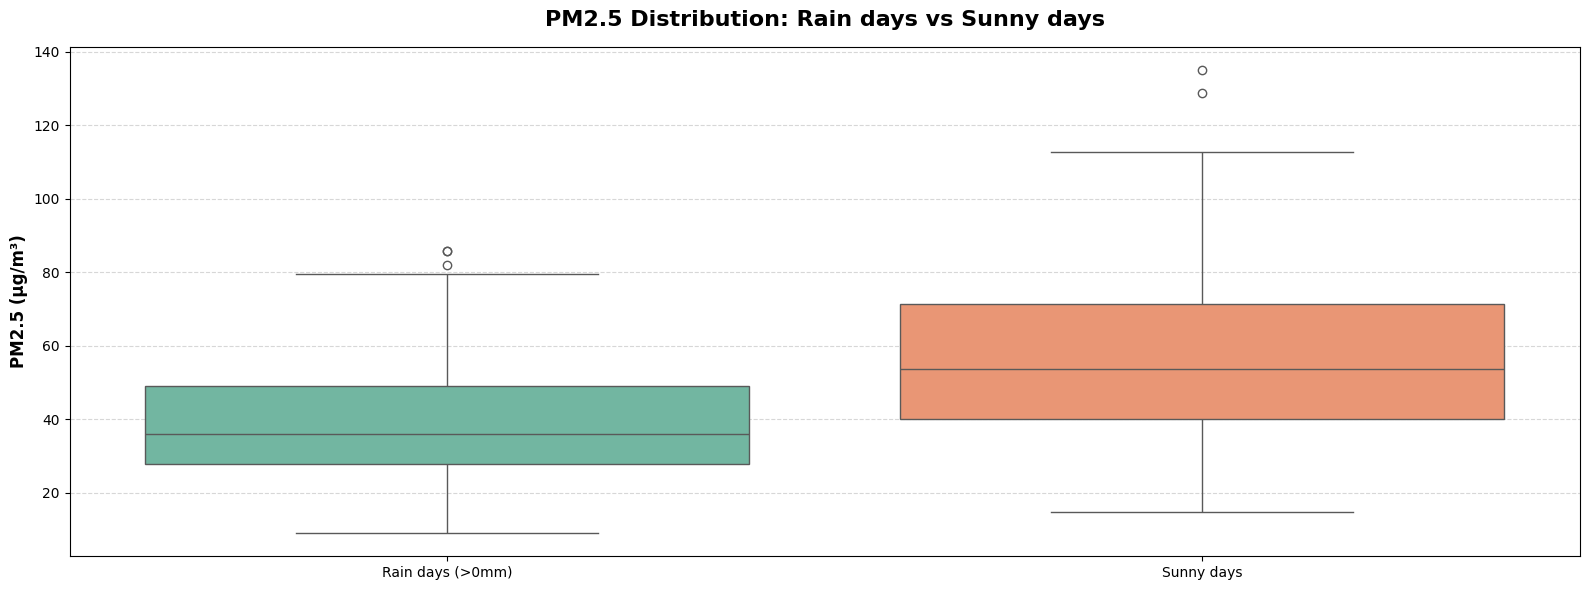

In [71]:
df_rain = clean_df[clean_df['is_deleted'] == False].copy()
df_rain['filtered_rain'] = df_rain['prcp'].apply(lambda x: 'Rain days (>0mm)' if x > 0 else 'Sunny days')

fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(data=df_rain, x='filtered_rain', y='pm2_5 (μg/m³)', ax=ax, palette="Set2")

ax.set_title('PM2.5 Distribution: Rain days vs Sunny days', fontweight='bold', fontsize=16, pad=15)
ax.set_xlabel('', fontweight="bold")
ax.set_ylabel('PM2.5 (µg/m³)', fontweight="bold", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.savefig("../figures/rain_days_and_pm2.5_corr.png", dpi=300, bbox_inches='tight')
plt.show()

## Wind speed & PM2.5 correlation

C:\Users\Admin\AppData\Local\Temp\ipykernel_4140\1770034017.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_wind, x='filtered_wspd', y='pm2_5 (μg/m³)', ax=ax, palette="Set2")


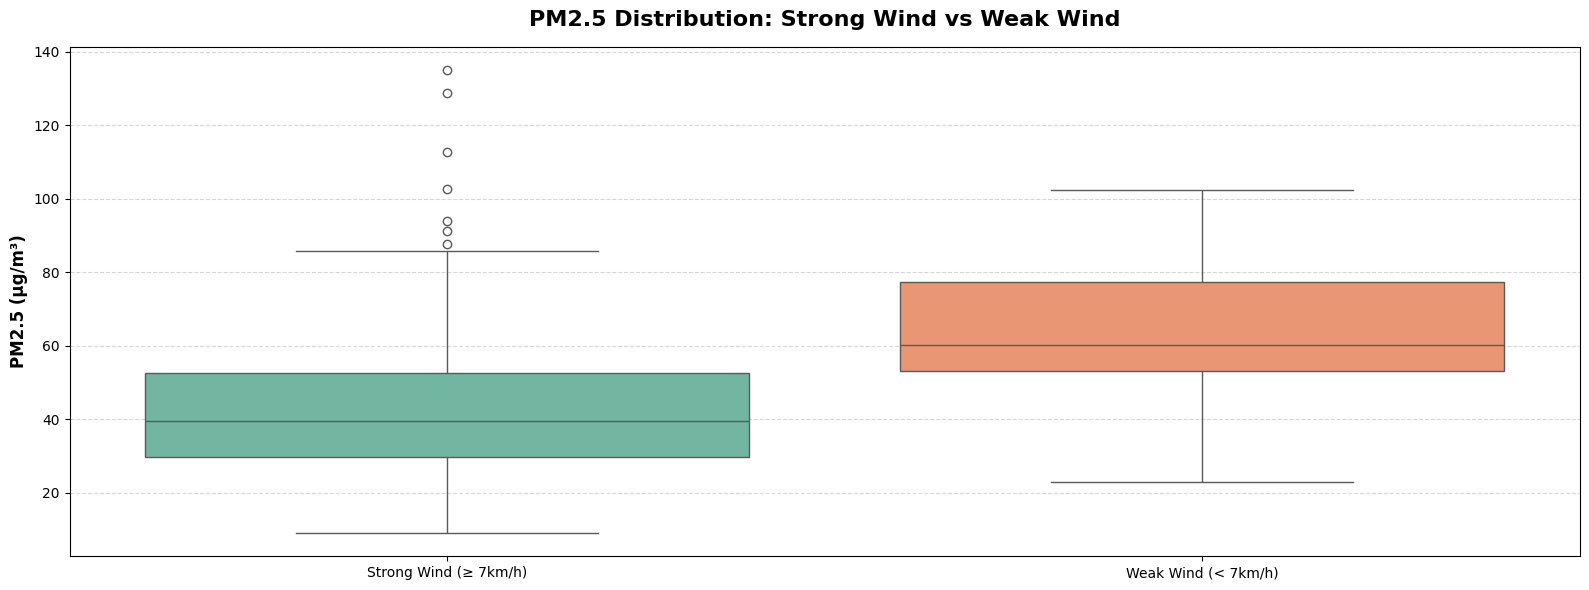

In [72]:
df_wind = clean_df[clean_df['is_deleted'] == False].copy()
df_wind['filtered_wspd'] = df_wind['wspd'].apply(lambda x: 'Strong Wind (≥ 7km/h)' if x >= 7 else 'Weak Wind (< 7km/h)')

fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(data=df_wind, x='filtered_wspd', y='pm2_5 (μg/m³)', ax=ax, palette="Set2")

ax.set_title('PM2.5 Distribution: Strong Wind vs Weak Wind', fontweight='bold', fontsize=16, pad=15)
ax.set_xlabel('')
ax.set_ylabel('PM2.5 (µg/m³)', fontweight="bold", fontsize=12)
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.savefig("../figures/wspd_and_pm2.5_corr.png", dpi=300, bbox_inches='tight')
plt.show()

## UV Index & UV clear sky

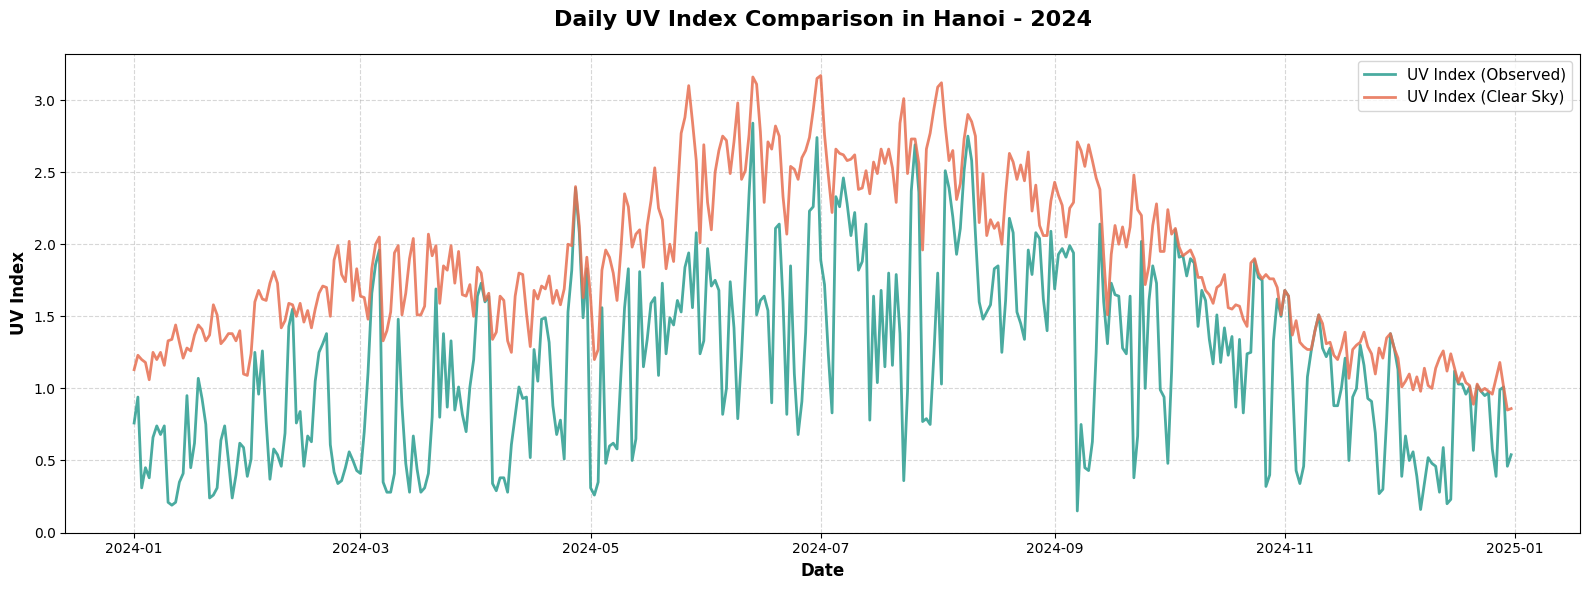

In [74]:
fig, ax = plt.subplots(figsize=(16, 6))

ax.plot(clean_df.index, clean_df['uv_index ()'], 
        color="#2A9D8F", linewidth=2, alpha=0.85, label='UV Index (Observed)')

ax.plot(clean_df.index, clean_df['uv_index_clear_sky ()'], 
        color="#E76F51", linewidth=2, alpha=0.85, label='UV Index (Clear Sky)')

ax.set_title('Daily UV Index Comparison in Hanoi - 2024', 
             fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Date', fontsize=12, fontweight='bold')
ax.set_ylabel('UV Index', fontsize=12, fontweight='bold')
ax.legend(loc='upper right', fontsize=11, frameon=True)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig("../figures/uv_index_over_time.png", dpi=300, bbox_inches='tight')
plt.show()